# MOMARL Results Visualization

Visualize Multi-Objective Multi-Agent RL training results from WandB logs.

**Features:** Pareto front, hypervolume comparison, hypervolume learning curve

## 1. Configuration

In [1]:
from pathlib import Path

# Paths
RESULTS_DIR = Path("../../momarl_wandb_logs/algo_comparison_v3_fixed")
OUTPUT_DIR = Path("./figures/RL_training")

# Hypervolume reference point (origin for maximization)
HYPERVOLUME_REF_POINT = [0.0, 0.0]

# Objective names for axis labels
# objectives are: "global_economic_output", "welfare", "temperature_threshold", "inverse_global_temperature"
OBJECTIVE_NAMES = ["inverse_global_temperature", "global_economic_output", ]  

# Plot settings
ALGORITHM_COMPARISON = True  # Set to False to plot only one algorithm
COLORS = {"HAPPO": "#033980", "HASAC": "#f6aa1e", "MAPPO": "#e15eb8", "UNKNOWN": "#ff8598"}
FIGURE_DPI = 150
SAVE_FIGURES = True

# Filter runs with returns below these thresholds (set to None to disable)
MIN_RETURN_OBJ_0 = 0.0
MIN_RETURN_OBJ_1 = 0.0

# WandB settings
USE_WANDB_API = False
WANDB_PROJECT = "momarl_algorithm_comparison"
WANDB_ENTITY = "olaandrasz-tu-delft"


## 2. Imports

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from dataclasses import dataclass
import warnings

# Hypervolume (DEAP)
try:
    from deap.tools._hypervolume import hv
    HV_AVAILABLE = True
except ImportError:
    HV_AVAILABLE = False
    warnings.warn("DEAP not installed - hypervolume unavailable")

# WandB
try:
    import wandb
    WANDB_AVAILABLE = True
except ImportError:
    WANDB_AVAILABLE = False
    warnings.warn("wandb not installed")

if SAVE_FIGURES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"HV: {HV_AVAILABLE}, WandB: {WANDB_AVAILABLE}")

if WANDB_AVAILABLE and USE_WANDB_API:
    try:
        wandb.login()
        print("WandB login successful")
    except Exception as e:
        print(f"WandB login failed: {e}")

HV: True, WandB: True


## 3. Data Loading

In [3]:
def load_json(path: Path) -> Optional[Dict]:
    if not path.exists():
        return None
    with open(path, 'r') as f:
        return json.load(f)

def load_yaml(path: Path) -> Optional[Dict]:
    if not path.exists():
        return None
    import yaml
    with open(path, 'r') as f:
        return yaml.safe_load(f)


def parse_run(run_dir: Path) -> Optional[Dict]:
    """Parse a single WandB run directory into a dict."""
    metadata = load_json(run_dir / "files" / "wandb-metadata.json")
    summary = load_json(run_dir / "files" / "wandb-summary.json")
    config = load_yaml(run_dir / "files" / "config.yaml")
    eval_folder = run_dir / "files" / "media" / "table" / "eval"
    
    # Find the last step file in the eval folder
    last_step_file = load_json(sorted(eval_folder.glob("objective_vector_*.table.json"))[-1]) if eval_folder.exists() else None
    last_step_rewards = last_step_file["data"][0] if last_step_file else None
    
    if metadata is None or summary is None:
        return None
    
    run_name = run_dir.name
    weights = summary.get("weights", [0.5, 0.5])
    rewards = config.get("rewards", {}).get("value", []) if config else []
    seed_idx = metadata.get("args", []).index("--seed") + 1 if "--seed" in metadata.get("args", []) else None
    return {
        "run_id": run_name,
        "seed":  metadata.get("args", [])[seed_idx] if seed_idx is not None else "1",
        "algorithm": config.get("algorithm", {}).get("value", "UNKNOWN").upper() if config else "UNKNOWN",
        "weight_0": weights[0] if weights else 0.0,
        "weight_1": weights[1] if len(weights) > 1 else 0.0,
        "weight_idx": summary.get("weight_idx", -1),
        "reward_0": rewards[0] if len(rewards) > 0 else "",
        "reward_1": rewards[1] if len(rewards) > 1 else "",
        "return_obj_0": last_step_rewards[0] if last_step_rewards else summary.get("eval/0_mean") or summary.get("final/return_obj_0") or 0.0,
        "return_obj_1": last_step_rewards[1] if last_step_rewards else summary.get("eval/1_mean") or summary.get("final/return_obj_1") or 0.0,
        "total_steps": summary.get("total_num_steps", 0),
        "weight_run_name": config.get("weight_run_name", {}).get("value", "") if config else "",
    }


def load_all_runs(results_dir: Path) -> pd.DataFrame:
    """Load all WandB runs from a directory into a DataFrame."""
    run_dirs = sorted([d for d in results_dir.iterdir() if d.is_dir() and (d.name.startswith("run-") or d.name.startswith("offline-run-"))])
    print(len(run_dirs), "runs found in", results_dir)
    rows = [parse_run(d) for d in run_dirs]
    rows = [r for r in rows if r is not None]
    return pd.DataFrame(rows) if rows else pd.DataFrame()

## 4. Load Runs

In [49]:
df = load_all_runs(RESULTS_DIR)

print(f"Loaded {len(df)} runs from {RESULTS_DIR}")

print(df["reward_0"].value_counts())
print(df["reward_1"].value_counts())

# Filter based on OBJECTIVE_0 and OBJECTIVE_1 names
if OBJECTIVE_NAMES[0] and OBJECTIVE_NAMES[1]:
    df = df[
        (df["reward_0"] == OBJECTIVE_NAMES[0]) &
        (df["reward_1"] == OBJECTIVE_NAMES[1])
    ]
df = df[(df['seed'] != '5')]  
print(f"\nAfter filtering by reward names: {len(df)} runs")
print(df["algorithm"].value_counts())

print(df["reward_0"].value_counts())
print(df["reward_1"].value_counts())

per_seed_counts = {}
print("Seed distribution:")
for seed, count in df["seed"].value_counts().items():
    per_seed_counts[seed] = {algo: df[(df['seed'] == seed) & (df['algorithm'] == algo)].shape[0] for algo in df['algorithm'].unique()}

per_seed_counts_df = pd.DataFrame(per_seed_counts).T.fillna(0).astype(int)
print(per_seed_counts_df)
#df.sort_values(by="seed", ascending=False).head(10)

1437 runs found in ../../momarl_wandb_logs/algo_comparison_v3_fixed
Loaded 1435 runs from ../../momarl_wandb_logs/algo_comparison_v3_fixed
reward_0
inverse_global_temperature    1435
Name: count, dtype: int64
reward_1
global_economic_output    1435
Name: count, dtype: int64

After filtering by reward names: 1185 runs
algorithm
HASAC    400
HAPPO    394
MAPPO    391
Name: count, dtype: int64
reward_0
inverse_global_temperature    1185
Name: count, dtype: int64
reward_1
global_economic_output    1185
Name: count, dtype: int64
Seed distribution:
   MAPPO  HAPPO  HASAC
1    100    100    100
4    100    100    100
2    100     99    100
3     91     95    100


## 5. Pareto Front

In [45]:
MARKERS = {"HAPPO": "o", "HASAC": "^", "MAPPO": "s", "UNKNOWN": "o"}

# Plotly markers (different naming)
PLOTLY_MARKERS = {"HAPPO": "circle", "HASAC": "triangle-up", "MAPPO": "square", "UNKNOWN": "circle"}

# Two-column paper figure sizes (inches)
# Single column: ~3.5"  |  Double column: ~7"
FIG_SINGLE = (3.5, 2.8)
FIG_DOUBLE = (7.0, 2.8)
FONT_SIZE_LABEL = 8
FONT_SIZE_TICK = 7
FONT_SIZE_LEGEND = 7
FONT_SIZE_ANNOT = 6
MAX_TICKS = 5  # Maximum number of ticks on each axis

from matplotlib.ticker import MaxNLocator

try:
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False
    print("Plotly not installed - interactive plots unavailable")


def is_pareto_efficient(points: np.ndarray) -> np.ndarray:
    """Return boolean mask of Pareto-efficient points (maximization)."""
    n = len(points)
    is_efficient = np.ones(n, dtype=bool)
    for i in range(n):
        for j in range(n):
            if i != j and np.all(points[j] >= points[i]) and np.any(points[j] > points[i]):
                is_efficient[i] = False
                break
    return is_efficient


def plot_pareto_front_interactive(df: pd.DataFrame) -> go.Figure:
    """Plot interactive Pareto front with hover info (weight, run_id).
    Includes checkbox to show/hide dominated (non-Pareto) points."""
    fig = go.Figure()
    
    algos = list(df["algorithm"].unique())
    if not ALGORITHM_COMPARISON and len(algos) > 1:
        # When only a single algorithm should be shown, select the most frequent one
        algos = [df["algorithm"].value_counts().idxmax()]
    
    dominated_trace_indices = []  # Track indices of dominated point traces
    trace_idx = 0
    
    for algo in algos:
        algo_df = df[df["algorithm"] == algo].reset_index(drop=True)
        points = algo_df[["return_obj_0", "return_obj_1"]].values
        color = COLORS.get(algo, "#333")
        marker = PLOTLY_MARKERS.get(algo, "circle")
        
        pareto_mask = is_pareto_efficient(points) if len(points) > 0 else np.zeros(len(points), dtype=bool)
        non_pareto_mask = ~pareto_mask
        
        # Create hover text with weight and run_id
        hover_text = [
            f"Run: {row['run_id']}<br>Weight: ({row['weight_0']:.2f}, {row['weight_1']:.2f})<br>"
            f"Model dir: {row['weight_run_name']}<br>Seed: {row['seed']}<br>"
            f"{OBJECTIVE_NAMES[0]}: {row['return_obj_0']:.2f}<br>{OBJECTIVE_NAMES[1]}: {row['return_obj_1']:.2f}"
            for _, row in algo_df.iterrows()
        ]
        
        # Add dominated (non-Pareto) points first (faded, hidden by default)
        if non_pareto_mask.any():
            non_pareto_df = algo_df[non_pareto_mask]
            non_pareto_hover = [hover_text[i] for i in range(len(algo_df)) if non_pareto_mask[i]]
            fig.add_trace(go.Scatter(
                x=non_pareto_df["return_obj_0"],
                y=non_pareto_df["return_obj_1"],
                mode="markers",
                marker=dict(size=10, color=color, symbol=marker, opacity=0.4,
                           line=dict(width=1, color="gray")),
                name=f"{algo} (dominated)",
                hovertemplate="%{customdata}<extra></extra>",
                customdata=non_pareto_hover,
                visible=False  # Hidden by default
            ))
            dominated_trace_indices.append(trace_idx)
            trace_idx += 1
        
        # Add Pareto points (highlighted)
        if pareto_mask.any():
            pareto_df = algo_df[pareto_mask]
            pareto_hover = [hover_text[i] for i in range(len(algo_df)) if pareto_mask[i]]
            fig.add_trace(go.Scatter(
                x=pareto_df["return_obj_0"],
                y=pareto_df["return_obj_1"],
                mode="markers",
                marker=dict(size=14, color=color, symbol=marker, 
                           line=dict(width=2, color="gray")),
                name=f"{algo} (Pareto)",
                hovertemplate="%{customdata}<extra></extra>",
                customdata=pareto_hover
            ))
            trace_idx += 1
    
    # Create visibility arrays for toggle buttons
    n_traces = len(fig.data)
    # Pareto only: dominated traces hidden
    pareto_only_visible = [True] * n_traces
    for i in dominated_trace_indices:
        pareto_only_visible[i] = False
    
    # All points: everything visible
    all_visible = [True] * n_traces
    
    title_text = "Pareto Front"
    if ALGORITHM_COMPARISON:
        title_text += ": HAPPO vs HASAC vs MAPPO"
    
    fig.update_layout(
        title=dict(text=title_text, font=dict(size=16, weight="bold")),
        xaxis_title=OBJECTIVE_NAMES[0].replace('_', ' ').title(),
        yaxis_title=OBJECTIVE_NAMES[1].replace('_', ' ').title(),
        legend=dict(x=0.98, y=0.98, xanchor="right", yanchor="bottom"),
        hovermode="closest",
        width=900,
        height=650,
        # Add toggle buttons
        updatemenus=[
            dict(
                type="buttons",
                direction="left",
                buttons=[
                    dict(
                        args=[{"visible": pareto_only_visible}],
                        label="Pareto Only",
                        method="update"
                    ),
                    dict(
                        args=[{"visible": all_visible}],
                        label="Show All Points",
                        method="update"
                    ),
                ],
                pad={"r": 10, "t": 10},
                showactive=True,
                x=0.0,
                xanchor="left",
                y=1.12,
                yanchor="top"
            ),
        ],
    )
    
    return fig


def plot_pareto_front(df: pd.DataFrame, show_weights: bool = True) -> plt.Figure:
    """Plot Pareto front comparison between algorithms (static matplotlib).
    Sized for a single column in a two-column paper."""
    fig, ax = plt.subplots(figsize=FIG_SINGLE)
    
    algos = list(df["algorithm"].unique())
    if not ALGORITHM_COMPARISON and len(algos) > 1:
        algos = [df["algorithm"].value_counts().idxmax()]
    
    for algo in algos:
        algo_df = df[df["algorithm"] == algo]
        points = algo_df[["return_obj_0", "return_obj_1"]].values
        color, marker = COLORS.get(algo, "#333"), MARKERS.get(algo, "x")
        
        pareto_mask = is_pareto_efficient(points) if len(points) > 0 else np.zeros(len(points), dtype=bool)
        
        # Pareto (highlighted)
        if pareto_mask.any():
            if ALGORITHM_COMPARISON:
                ax.scatter(points[pareto_mask, 0], points[pareto_mask, 1],
                      c=color, s=40, marker=marker, alpha=0.9,
                      edgecolors='black', linewidths=0.8, label=f"{algo}")
            else:
                ax.scatter(points[pareto_mask, 0], points[pareto_mask, 1],
                      c=color, s=40, marker=marker, alpha=0.9,
                      edgecolors='gray', linewidths=0.8, label=f"{OBJECTIVE_NAMES}")
        
        # Weight annotations
        if show_weights:
            for _, row in algo_df.iterrows():
                ax.annotate(f"({row['weight_0']:.2f}, {row['weight_1']:.2f})",
                           (row["return_obj_0"], row["return_obj_1"]),
                           textcoords="offset points", xytext=(3, 3 if algo == "HAPPO" else -8),
                           fontsize=FONT_SIZE_ANNOT, color=color, alpha=0.8)
    
    ax.set_xlabel(OBJECTIVE_NAMES[0].replace('_', ' ').title(), fontsize=FONT_SIZE_LABEL)
    ax.set_ylabel(OBJECTIVE_NAMES[1].replace('_', ' ').title(), fontsize=FONT_SIZE_LABEL)
    ax.tick_params(axis='both', labelsize=FONT_SIZE_TICK)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.set_title("Pareto Front", fontsize=9, fontweight='bold')
    ax.legend(loc='lower left', fontsize=FONT_SIZE_LEGEND)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig


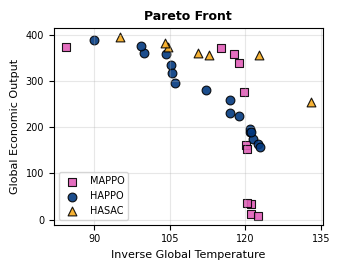


Pareto front runs per algorithm:
Pareto front runs for MAPPO: 11 runs
Pareto front runs for HAPPO: 17 runs
Pareto front runs for HASAC: 7 runs


In [50]:
# Interactive plot with hover (Plotly)
if PLOTLY_AVAILABLE:
    fig_pareto_interactive = plot_pareto_front_interactive(df) #df[df['algorithm'] == 'HASAC'])
    fig_pareto_interactive.show()
else:
    print("Plotly not available, showing static plot")

# Static plot (matplotlib) - for saving
fig_pareto = plot_pareto_front(df, show_weights=False)
#fig_pareto.title("Pareto Front: HAPPO vs HASAC vs MAPPO", fontsize=9, fontweight='bold')
if SAVE_FIGURES:
    fig_pareto.savefig(OUTPUT_DIR / "pareto_front.png", dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

# Print pareto front runs per algorithm to a file
print("\nPareto front runs per algorithm:")
for algo in df["algorithm"].unique():
    algo_df = df[df["algorithm"] == algo]
    points = algo_df[["return_obj_0", "return_obj_1"]].values
    pareto_mask = is_pareto_efficient(points) if len(points) > 0 else np.zeros(len(points), dtype=bool)
    pareto_runs = algo_df[pareto_mask]
    
    with open(OUTPUT_DIR / f"pareto_runs_{algo}.txt", "w") as f:
        print(f"Pareto front runs for {algo}: {len(pareto_runs)} runs")
        f.write(f"Pareto front runs for {algo}:\n")
        for _, row in pareto_runs.iterrows():
            f.write(f"Run ID: {row['weight_run_name']}, seed {row['seed']}, weight: {int(row['weight_0']*100)}\n")
            

## 6. Hypervolume Over Time

In [9]:
def _parse_wandb_file(wandb_file: Path) -> List[Dict]:
    """Parse a .wandb binary file and return history records as list of dicts."""
    from wandb.sdk.internal import datastore
    from wandb.proto import wandb_internal_pb2
    
    ds = datastore.DataStore()
    ds.open_for_scan(str(wandb_file))
    
    records = []
    errors = 0
    while True:
        try:
            data = ds.scan_record()
        except Exception:
            errors += 1
            if errors > 50:
                break
            continue
        if data is None:
            break
        try:
            pb = wandb_internal_pb2.Record()
            pb.ParseFromString(data[1])
        except Exception:
            errors += 1
            continue
        if pb.WhichOneof("record_type") == "history":
            items = {}
            for item in pb.history.item:
                key = item.nested_key[0] if item.nested_key else item.key
                items[key] = item.value_json
            records.append(items)
    return records


def _parse_objective_vector_value(val_str: str, run_dir: Path) -> Optional[np.ndarray]:
    """Parse an objective_vector value from a history record.
    It can be a path to a table JSON file under files/, or inline JSON."""
    if val_str.startswith('"') and val_str.endswith('"'):
        val_str = val_str.strip('"')
    
    # Check if it's a media/table path
    if val_str.startswith("media/"):
        table_path = run_dir / "files" / val_str
        if table_path.exists():
            with open(table_path, "r") as f:
                table = json.load(f)
            return np.array(table["data"])
        return None
    
    # Try parsing as JSON
    try:
        parsed = json.loads(val_str)
        if isinstance(parsed, dict) and "data" in parsed:
            return np.array(parsed["data"])
        elif isinstance(parsed, list):
            return np.array(parsed)
    except Exception:
        pass
    return None


def _fetch_history_from_local(run_dir: Path, run_id: str, seed: str, algorithm: str) -> Optional[pd.DataFrame]:
    """Parse training history from a local offline wandb run directory."""
    wandb_files = list(run_dir.glob("run-*.wandb"))
    if not wandb_files:
        return None
    
    records = _parse_wandb_file(wandb_files[0])
    if not records:
        return None
    
    # Separate eval records (have eval/ keys) from training records
    eval_rows = []
    for rec in records:
        step = rec.get("_step")
        if step is None:
            continue
        step = int(float(step))
        
        # Check for eval keys
        obj_0 = rec.get("eval/0_mean")
        obj_1 = rec.get("eval/1_mean")
        total_steps = rec.get("eval/total_num_steps") or rec.get("total_num_steps")
        obj_vec_ref = rec.get("eval/objective_vector")
        
        if obj_0 is not None or obj_1 is not None:
            obj_vec = None
            if obj_vec_ref is not None:
                obj_vec = _parse_objective_vector_value(obj_vec_ref, run_dir)
            
            eval_rows.append({
                "seed": seed,
                "total_num_steps": float(total_steps) if total_steps else np.nan,
                "0": float(obj_0) if obj_0 else np.nan,
                "1": float(obj_1) if obj_1 else np.nan,
                "objective_vectors": obj_vec,
                "run_id": run_id,
                "algorithm": algorithm,
            })
    
    if not eval_rows:
        # Fallback: look for records with '0' and '1' keys (older format)
        for rec in records:
            obj_0 = rec.get("0")
            obj_1 = rec.get("1")
            total_steps = rec.get("total_num_steps")
            if obj_0 is not None and obj_1 is not None:
                eval_rows.append({
                    "seed": seed,
                    "total_num_steps": float(total_steps) if total_steps else np.nan,
                    "0": float(obj_0),
                    "1": float(obj_1),
                    "objective_vectors": None,
                    "run_id": run_id,
                    "algorithm": algorithm,
                })
    
    if not eval_rows:
        return None
    
    df = pd.DataFrame(eval_rows)
    df["total_num_steps"] = df["total_num_steps"].ffill().bfill()
    return df


def fetch_training_history_from_wandb(runs_df, entity: str, project: str) -> Dict[str, pd.DataFrame]:
    """Fetch eval history for all runs from WandB API or local .wandb files.
    Returns histories dict with algorithm info embedded in each DataFrame.
    Columns: run_id, algorithm, total_num_steps, 0, 1, objective_vectors (list of arrays)."""
    if USE_WANDB_API:
        api = wandb.Api()
    
    histories = {}
    i = 0 
    for run_id, algorithm in zip(runs_df["run_id"], runs_df["algorithm"]):
        
        run_new_id = run_id.split("-")[-1] if "-" in run_id else run_id
        seed = runs_df[runs_df["run_id"] == run_id]["seed"].iloc[0]
        if i % 50 == 0:
            print(f"Fetching history for run {i}/{len(runs_df)}")
        i += 1
        try:
            if USE_WANDB_API:
                online_data = api.run(f"{entity}/{project}/{run_new_id}")
            else:
                # Parse from local .wandb file
                run_dir = RESULTS_DIR / run_id
                hist_df = _fetch_history_from_local(run_dir, run_id, seed, algorithm)
                if hist_df is not None and len(hist_df) > 0:
                    histories[run_id] = hist_df
                continue
        except Exception as e:
            print(f"Failed to fetch run with path {entity}/{project}/{run_new_id}: \n{e}")
            continue
    
        # Fetch each key separately to avoid wandb dropping rows where not all keys are present
        hist_0_means = online_data.history(keys=["eval/0_mean"], pandas=True)
        hist_1_means = online_data.history(keys=["eval/1_mean"], pandas=True)
        hist_total_steps = online_data.history(keys=["total_num_steps"], pandas=True)
        hist_objective_vector = online_data.history(keys=["eval/objective_vector"], pandas=True)
        
        if hist_0_means.empty and hist_1_means.empty:
            print(f"No eval data for {run_new_id}, skipping")
            continue
        
        # Merge on _step index (wandb adds _step column to each history call)
        history_df = pd.DataFrame({"_step": hist_0_means.get("_step", pd.Series(dtype=int))})
        history_df["0"] = hist_0_means.get("eval/0_mean", pd.Series(dtype=float)).values
        
        if not hist_1_means.empty and "_step" in hist_1_means.columns:
            h1 = hist_1_means[["_step", "eval/1_mean"]].rename(columns={"eval/1_mean": "1"})
            history_df = history_df.merge(h1, on="_step", how="outer")
        else:
            history_df["1"] = np.nan
        
        if not hist_total_steps.empty and "_step" in hist_total_steps.columns:
            ht = hist_total_steps[["_step", "total_num_steps"]]
            history_df = history_df.merge(ht, on="_step", how="outer")
        else:
            history_df["total_num_steps"] = np.nan
        
        history_df = history_df.sort_values("_step").reset_index(drop=True)
        history_df["total_num_steps"] = history_df["total_num_steps"].ffill().bfill()
        history_df["run_id"] = run_id
        
        history_df["algorithm"] = algorithm
        
        # Parse objective_vector column: wandb Tables come back as dicts or strings
        obj_vectors = []
        vec_col = hist_objective_vector.get("eval/objective_vector")
        vec_steps = hist_objective_vector.get("_step")
        
        # Build a step -> vector mapping
        vec_by_step = {}
        if vec_col is not None and vec_steps is not None:
            for step_val, val in zip(vec_steps, vec_col):
                if val is None or (isinstance(val, float) and np.isnan(val)):
                    vec_by_step[step_val] = None
                elif isinstance(val, dict) and "data" in val:
                    vec_by_step[step_val] = np.array(val["data"])
                elif isinstance(val, list):
                    vec_by_step[step_val] = np.array(val)
                elif isinstance(val, str):
                    import json as _json
                    try:
                        parsed = _json.loads(val)
                        if isinstance(parsed, dict) and "data" in parsed:
                            vec_by_step[step_val] = np.array(parsed["data"])
                        else:
                            vec_by_step[step_val] = np.array(parsed)
                    except Exception:
                        vec_by_step[step_val] = None
                else:
                    vec_by_step[step_val] = None
        
        # Align vectors with history_df rows by _step
        history_df["objective_vectors"] = [vec_by_step.get(s) for s in history_df["_step"]]
        history_df = history_df.drop(columns=["_step"])
        
        histories[run_id] = history_df
    return histories

In [51]:
# print("Fetching from WandB API...")
# api = wandb.Api()
# print(api.runs(f"{WANDB_ENTITY}/{WANDB_PROJECT}"))
# for run in api.runs(f"{WANDB_ENTITY}/{WANDB_PROJECT}"):
#     print(run.path)
# print(WANDB_ENTITY, WANDB_PROJECT)

In [52]:
if WANDB_AVAILABLE and USE_WANDB_API and HV_AVAILABLE:
    print("Fetching from WandB API...")
    api = wandb.Api()
    # print(api.runs(f"{WANDB_ENTITY}/{WANDB_PROJECT}"))
    # for run in api.runs(f"{WANDB_ENTITY}/{WANDB_PROJECT}"):
    #     print(run.path)
    print(WANDB_ENTITY, WANDB_PROJECT)
    histories = fetch_training_history_from_wandb(df, WANDB_ENTITY, WANDB_PROJECT)
    
    # Extract algorithms from histories
    algos_found = {hist["algorithm"].iloc[0] for hist in histories.values() if len(hist) > 0}
    print(f"\nLoaded {len(histories)} runs, algorithms: {algos_found} with seeds: {set(df['seed'].unique())}")
else:
    print("Offline mode: skipping WandB API fetch")
    histories = fetch_training_history_from_wandb(df, WANDB_ENTITY, WANDB_PROJECT)
    algos_found = {hist["algorithm"].iloc[0] for hist in histories.values() if len(hist) > 0}
    print(f"\nLoaded {len(histories)} runs, algorithms: {algos_found} with seeds: {set(df['seed'].unique())}")

Offline mode: skipping WandB API fetch
Fetching history for run 0/1185
Fetching history for run 50/1185
Fetching history for run 100/1185
Fetching history for run 150/1185
Fetching history for run 200/1185
Fetching history for run 250/1185
Fetching history for run 300/1185
Fetching history for run 350/1185
Fetching history for run 400/1185
Fetching history for run 450/1185
Fetching history for run 500/1185
Fetching history for run 550/1185
Fetching history for run 600/1185
Fetching history for run 650/1185
Fetching history for run 700/1185
Fetching history for run 750/1185
Fetching history for run 800/1185
Fetching history for run 850/1185
Fetching history for run 900/1185
Fetching history for run 950/1185
Fetching history for run 1000/1185
Fetching history for run 1050/1185
Fetching history for run 1100/1185
Fetching history for run 1150/1185

Loaded 1185 runs, algorithms: {'MAPPO', 'HASAC', 'HAPPO'} with seeds: {'4', '3', '1', '2'}


In [53]:

# ── Diagnostic: compare df runs vs successfully parsed histories ──────────────
history_run_ids = set(histories.keys())
df_run_ids      = set(df["run_id"])

print(f"Runs in df:        {len(df_run_ids)}")
print(f"Runs in histories: {len(history_run_ids)}")
print(f"In df but missing from histories: {len(df_run_ids - history_run_ids)}")
print(f"In histories but not in df:       {len(history_run_ids - df_run_ids)}")

print("\n--- Per-algorithm breakdown ---")
for algo in sorted(df["algorithm"].unique()):
    algo_df_ids   = set(df[df["algorithm"] == algo]["run_id"])
    algo_hist_ids = {rid for rid in history_run_ids
                     if rid in histories and histories[rid]["algorithm"].iloc[0] == algo}
    missing       = algo_df_ids - algo_hist_ids
    print(f"  {algo:8s}  df={len(algo_df_ids):3d}  histories={len(algo_hist_ids):3d}  "
          f"missing={len(missing):3d}"
          + (f"  ← {sorted(missing)[:5]}{'...' if len(missing) > 5 else ''}" if missing else ""))

print("\n--- Total steps per algorithm (from histories) ---")
for algo in sorted(df["algorithm"].unique()):
    algo_steps = [
        histories[rid]["total_num_steps"].max()
        for rid in history_run_ids
        if rid in histories and histories[rid]["algorithm"].iloc[0] == algo
           and not histories[rid]["total_num_steps"].isna().all()
    ]
    if algo_steps:
        print(f"  {algo:8s}  min_steps={min(algo_steps):.0f}  "
              f"max_steps={max(algo_steps):.0f}  "
              f"mean_steps={sum(algo_steps)/len(algo_steps):.0f}  "
              f"n_runs={len(algo_steps)}")


Runs in df:        1185
Runs in histories: 1185
In df but missing from histories: 0
In histories but not in df:       0

--- Per-algorithm breakdown ---
  HAPPO     df=394  histories=394  missing=  0
  HASAC     df=400  histories=400  missing=  0
  MAPPO     df=391  histories=391  missing=  0

--- Total steps per algorithm (from histories) ---
  HAPPO     min_steps=82500  max_steps=1980000  mean_steps=1726846  n_runs=394
  HASAC     min_steps=51250  max_steps=1000000  mean_steps=937300  n_runs=400
  MAPPO     min_steps=82500  max_steps=1980000  mean_steps=1773223  n_runs=391


In [13]:
from morl_baselines.common.performance_indicators import hypervolume
from morl_baselines.common.pareto import filter_pareto_dominated

def compute_hypervolume_over_time(histories: Dict[str, pd.DataFrame],
                                   ref_point: List[float], num_bins: int = 100) -> Dict[str, Tuple[np.ndarray, np.ndarray, np.ndarray]]:
    """
    Compute hypervolume over time for each algorithm, returning dict of algo -> (steps, hv_mean, hv_std).

    Runs are grouped by (algorithm, seed). For each seed, HV is computed over the combined
    normalized point set of all runs belonging to that seed. Mean and std are then computed
    across seeds, and std is used as the shaded area in the plot.

    Points are min-max normalized across ALL runs and algorithms before HV computation.
    Each algorithm uses its own step grid so algorithms with fewer steps are not padded.
    """
    # Compute global normalization bounds across ALL runs
    all_obj0, all_obj1 = [], []
    for hist in histories.values():
        valid = hist.dropna(subset=["total_num_steps", "0", "1"])
        all_obj0.extend(valid["0"].tolist())
        all_obj1.extend(valid["1"].tolist())

    if not all_obj0:
        return {}

    min0, max0 = min(all_obj0), max(all_obj0)
    min1, max1 = min(all_obj1), max(all_obj1)
    range0 = max0 - min0 if max0 != min0 else 1.0
    range1 = max1 - min1 if max1 != min1 else 1.0

    def normalize(o0, o1):
        return (o0 - min0) / range0, (o1 - min1) / range1

    # Group histories by (algorithm, seed)
    # algo_seed_data: algo -> seed -> list of [(step, norm_o0, norm_o1), ...]
    algo_seed_data: Dict[str, Dict[str, List]] = {}
    for run_id, hist in histories.items():
        algo = hist["algorithm"].iloc[0] if len(hist) > 0 else "UNKNOWN"
        valid_rows = hist.dropna(subset=["total_num_steps", "0", "1"])
        if valid_rows.empty:
            continue
        seed = str(valid_rows["seed"].iloc[0]) if "seed" in valid_rows.columns else "1"
        pts = sorted(
            [(row["total_num_steps"], *normalize(row["0"], row["1"])) for _, row in valid_rows.iterrows()],
            key=lambda x: x[0]
        )
        if pts:
            algo_seed_data.setdefault(algo, {}).setdefault(seed, []).append(pts)

    ref = np.array(ref_point)
    results = {}
    for algo, seed_dict in algo_seed_data.items():
        print(f"Processing algorithm {algo} with {len(seed_dict)} seed(s)")
        seed_hv_curves = []

        # Per-algorithm step grid: only spans this algorithm's actual step range
        algo_steps = [s for run_data in seed_dict.values() for pts in run_data for s, _, _ in pts]
        step_grid = np.linspace(min(algo_steps), max(algo_steps), num_bins)

        for seed, run_data in seed_dict.items():
            hv_values = []
            for t in step_grid:
                current_points = []
                for pts in run_data:
                    past = [(o0, o1) for s, o0, o1 in pts if s <= t]
                    if past:
                        current_points.append(past[-1])

                if current_points:
                    pts_arr = np.array(current_points)
                    valid_pts = pts_arr[np.all(pts_arr > ref, axis=1)]
                    valid_pts = filter_pareto_dominated(valid_pts) if len(valid_pts) > 0 else valid_pts
                    hv_val = hypervolume(ref, valid_pts) if len(valid_pts) > 0 else 0.0
                else:
                    hv_val = 0.0
                hv_values.append(hv_val)

            seed_hv_curves.append(np.array(hv_values))

        if seed_hv_curves:
            hv_matrix = np.array(seed_hv_curves)  # shape: (n_seeds, num_bins)
            hv_mean = np.mean(hv_matrix, axis=0)
            hv_std = np.std(hv_matrix, axis=0)
            results[algo] = (step_grid, hv_mean, hv_std)

    return results


def plot_hypervolume_over_time(hv_over_time: Dict[str, Tuple[np.ndarray, np.ndarray, np.ndarray]]) -> plt.Figure:
    """Plot hypervolume learning curves. Sized for a single column in a two-column paper."""
    fig, ax = plt.subplots(figsize=FIG_SINGLE)
    
    for algo, data in hv_over_time.items():
        steps, hv_mean, hv_std = data
        color = COLORS.get(algo, "#333")
        label = algo if ALGORITHM_COMPARISON else f"{OBJECTIVE_NAMES}"
        
        ax.plot(steps, hv_mean, color=color, linewidth=1.2, label=label)
        ax.fill_between(steps, hv_mean - hv_std, hv_mean + hv_std,
                        color=color, alpha=0.15)
    
    ax.set_xlabel("Total Steps", fontsize=FONT_SIZE_LABEL)
    #ax.set_ylabel("Hypervolume (normalized)", fontsize=FONT_SIZE_LABEL)
    #ax.set_ylim([0.1, 0.9])
    ax.tick_params(axis='both', labelsize=FONT_SIZE_TICK)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.set_title(f"Hypervolume", fontsize=FONT_SIZE_LABEL, fontweight='bold')
    ax.legend(loc='lower right', fontsize=FONT_SIZE_LEGEND)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig


Processing algorithm MAPPO with 4 seed(s)
Processing algorithm HAPPO with 4 seed(s)
Processing algorithm HASAC with 4 seed(s)

--- Hypervolume Statistics ---
  MAPPO:  final=0.625 ± 0.073  avg=0.4964  max=0.6421  avg std=0.0665
  HAPPO:  final=0.695 ± 0.058  avg=0.4846  max=0.7297  avg std=0.0444
  HASAC:  final=0.771 ± 0.060  avg=0.7054  max=0.7711  avg std=0.0367


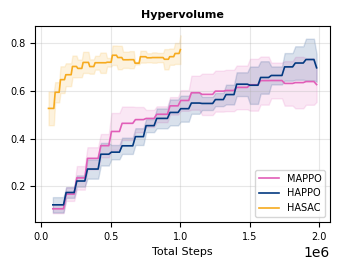

In [54]:
# for run_id in histories:
#     print(f"Run {run_id} - Algorithm: {histories[run_id]['algorithm'].iloc[0]}, "
#           f"Steps: {len(histories[run_id])}, "
#           f"Final 0: {histories[run_id]['0'].iloc[-1]:.2f}, "
#           f"Final 1: {histories[run_id]['1'].iloc[-1]:.2f}")
hv_over_time = compute_hypervolume_over_time(histories, HYPERVOLUME_REF_POINT)

if hv_over_time:
    print("\n--- Hypervolume Statistics ---")
    for algo, (steps, hv_mean, hv_std) in hv_over_time.items():
        print(f"  {algo}:  final={hv_mean[-1]:.3f} ± {hv_std[-1]:.3f}  "
              f"avg={hv_mean.mean():.4f}  max={hv_mean.max():.4f}  "
              f"avg std={hv_std.mean():.4f}")
    fig_hv_time = plot_hypervolume_over_time(hv_over_time)
    if SAVE_FIGURES:
        fig_hv_time.savefig(OUTPUT_DIR / "hypervolume_over_time.png", dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
else:
    print("No data for HV over time")


## 7. Expected Utility Over Time

In [15]:
from morl_baselines.common.performance_indicators import expected_utility
from morl_baselines.common.pareto import filter_pareto_dominated

def compute_expected_utility_over_time(histories: Dict[str, pd.DataFrame],
                                       runs_df: pd.DataFrame,
                                       num_bins: int = 100) -> Dict[str, Tuple[np.ndarray, np.ndarray, np.ndarray]]:
    """Compute expected utility (morl_baselines) over time for each algorithm.

    Runs are grouped by (algorithm, seed). For each seed, EU is computed over the
    combined front of all runs belonging to that seed. Mean and std are then computed
    across seeds. Each algorithm uses its own step grid.

    Returns: algo -> (steps, eu_mean, eu_std).
    """
    weights_lookup = {
        row["run_id"]: np.array([row["weight_0"], row["weight_1"]])
        for _, row in runs_df.iterrows()
    }

    # Global normalization bounds
    all_obj0, all_obj1 = [], []
    for hist in histories.values():
        valid = hist.dropna(subset=["total_num_steps", "0", "1"])
        all_obj0.extend(valid["0"].tolist())
        all_obj1.extend(valid["1"].tolist())

    if not all_obj0:
        return {}

    min0, max0 = min(all_obj0), max(all_obj0)
    min1, max1 = min(all_obj1), max(all_obj1)
    range0 = max0 - min0 if max0 != min0 else 1.0
    range1 = max1 - min1 if max1 != min1 else 1.0

    # Group by (algorithm, seed)
    # algo_seed_data: algo -> seed -> list of (run_id, [(step, norm_point), ...])
    algo_seed_data: Dict[str, Dict[str, List]] = {}
    for run_id, hist in histories.items():
        if len(hist) == 0:
            continue
        algo = hist["algorithm"].iloc[0] if "algorithm" in hist.columns else "UNKNOWN"
        valid_rows = hist.dropna(subset=["total_num_steps", "0", "1"])
        if valid_rows.empty:
            continue
        seed = str(valid_rows["seed"].iloc[0]) if "seed" in valid_rows.columns else "1"
        pts = sorted(
            [(row["total_num_steps"],
              np.array([(row["0"] - min0) / range0, (row["1"] - min1) / range1]))
             for _, row in valid_rows.iterrows()],
            key=lambda x: x[0]
        )
        if pts:
            algo_seed_data.setdefault(algo, {}).setdefault(seed, []).append((run_id, pts))

    results: Dict[str, Tuple[np.ndarray, np.ndarray, np.ndarray]] = {}
    for algo, seed_dict in algo_seed_data.items():
        print(f"Processing algorithm {algo} with {len(seed_dict)} seed(s)")
        seed_eu_curves = []

        # Per-algorithm step grid
        algo_steps = [s for seed_runs in seed_dict.values() for _, pts in seed_runs for s, _ in pts]
        step_grid = np.linspace(min(algo_steps), max(algo_steps), num_bins)

        for seed, seed_runs in seed_dict.items():
            # Collect all weights for this seed's runs
            seed_weights = [weights_lookup.get(run_id, np.array([0.5, 0.5])) for run_id, _ in seed_runs]
            run_pts_list = [pts for _, pts in seed_runs]

            eu_values = []
            for t in step_grid:
                front = []
                for pts in run_pts_list:
                    past = [p for s, p in pts if s <= t]
                    if past:
                        front.append(past[-1])
                front_arr = filter_pareto_dominated(np.array(front)) if front else np.array([])
                eu_val = expected_utility(front_arr, seed_weights) if front_arr.size > 0 else np.nan
                eu_values.append(eu_val)

            seed_eu_curves.append(np.array(eu_values))

        if seed_eu_curves:
            eu_matrix = np.array(seed_eu_curves)  # shape: (n_seeds, num_bins)
            eu_mean = np.nanmean(eu_matrix, axis=0)
            eu_std = np.nanstd(eu_matrix, axis=0)
            results[algo] = (step_grid, eu_mean, eu_std)

    return results


def plot_expected_utility_over_time(eu_over_time: Dict[str, Tuple[np.ndarray, np.ndarray, np.ndarray]]) -> plt.Figure:
    """Plot expected utility learning curves. Sized for a single column in a two-column paper."""
    fig, ax = plt.subplots(figsize=FIG_SINGLE)
    
    for algo, data in eu_over_time.items():
        steps, eu_mean, eu_std = data
        color = COLORS.get(algo, "#333")
        label = algo if ALGORITHM_COMPARISON else f"{OBJECTIVE_NAMES}"
        
        ax.plot(steps, eu_mean, color=color, linewidth=1.2, label=label)
        ax.fill_between(steps, eu_mean - eu_std, eu_mean + eu_std,
                        color=color, alpha=0.15)
    
    ax.set_xlabel("Total Steps", fontsize=FONT_SIZE_LABEL)
    #ax.set_ylabel("Expected Utility (normalized)", fontsize=FONT_SIZE_LABEL)
    #ax.set_ylim([0.1, 0.9])
    ax.tick_params(axis='both', labelsize=FONT_SIZE_TICK)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.set_title("Expected Utility", fontsize=FONT_SIZE_LABEL, fontweight='bold')
    ax.legend(loc='lower right', fontsize=FONT_SIZE_LEGEND)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig


Processing algorithm MAPPO with 4 seed(s)
Processing algorithm HAPPO with 4 seed(s)
Processing algorithm HASAC with 4 seed(s)

--- Expected Utility Statistics ---
  MAPPO:  final=0.754 ±0.049  avg=0.6722  max=0.7669
  HAPPO:  final=0.801 ±0.032  avg=0.6625  max=0.8239
  HASAC:  final=0.834 ±0.035  avg=0.8059  max=0.8374


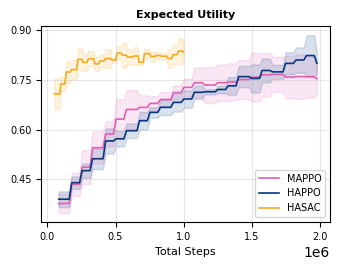

In [55]:
eu_over_time = compute_expected_utility_over_time(histories, df)

if eu_over_time:
    print("\n--- Expected Utility Statistics ---")
    for algo, (steps, eu_mean, eu_std) in eu_over_time.items():
        print(f"  {algo}:  final={eu_mean[-1]:.3f} ±{eu_std[-1]:.3f}  "
              f"avg={np.nanmean(eu_mean):.4f}  max={np.nanmax(eu_mean):.4f}")
    fig_eu_time = plot_expected_utility_over_time(eu_over_time)
    if SAVE_FIGURES:
        fig_eu_time.savefig(OUTPUT_DIR / "expected_utility_over_time.png", dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
else:
    print("No data for expected utility over time")


## 8. Training Time per Weight

In [20]:
def fetch_training_times(runs_df, entity: str, project: str) -> pd.DataFrame:
    """Fetch training duration per run from wandb system metrics.
    Returns DataFrame with columns: run_id, algorithm, weight_idx, weight_0, weight_1, duration_min."""
    api = wandb.Api()
    rows = []
    for _, row in runs_df.iterrows():
        run_id = row["run_id"]
        run_new_id = run_id.split("-")[-1] if "-" in run_id else run_id
        try:
            run_obj = api.run(f"{entity}/{project}/{run_new_id}")
            runtime_sec = run_obj.summary.get("_runtime", 0)
            rows.append({
                "run_id": run_id,
                "algorithm": row["algorithm"],
                "weight_0": row["weight_0"],
                "weight_1": row["weight_1"],
                "weight_idx": int(row["weight_0"]*100),
                "duration_min": runtime_sec / 60.0,
            })
        except Exception as e:
            print(f"Failed to fetch runtime for {run_new_id}: {e}")
    return pd.DataFrame(rows)


def plot_training_time(time_df: pd.DataFrame) -> plt.Figure:
    """Scatter + box plot of training time per weight index, grouped by algorithm.
    Sized for full double-column width in a two-column paper."""
    fig, axes = plt.subplots(1, 2, figsize=FIG_DOUBLE, gridspec_kw={"width_ratios": [3, 1]})
    
    algos = sorted(time_df["algorithm"].unique())
    
    # Left: scatter plot of duration vs weight_idx
    ax = axes[0]
    for algo in algos:
        algo_df = time_df[time_df["algorithm"] == algo].sort_values("weight_idx")
        color = COLORS.get(algo, "#333")
        marker = MARKERS.get(algo, "o")
        ax.scatter(algo_df["weight_idx"], algo_df["duration_min"],
                  c=color, marker=marker, s=12, alpha=0.7, label=algo,
                  edgecolors="gray", linewidths=0.3)
        
        # Mean line
        mean_dur = algo_df["duration_min"].mean()
        ax.axhline(mean_dur, color=color, linestyle="--", alpha=0.5, linewidth=0.8)
    
    ax.set_xlabel("Weight Index", fontsize=FONT_SIZE_LABEL)
    ax.set_ylabel("Training Time (min)", fontsize=FONT_SIZE_LABEL)
    ax.set_title("Training Time per Weight", fontsize=FONT_SIZE_LABEL, fontweight='bold')
    ax.tick_params(axis='both', labelsize=FONT_SIZE_TICK)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax.legend(loc='upper right', fontsize=FONT_SIZE_LEGEND)
    ax.grid(True, alpha=0.3)
    
    # Right: box plot per algorithm
    ax2 = axes[1]
    box_data = [time_df[time_df["algorithm"] == algo]["duration_min"].values for algo in algos]
    bp = ax2.boxplot(box_data, labels=algos, patch_artist=True, widths=0.5)
    for patch, algo in zip(bp["boxes"], algos):
        patch.set_facecolor(COLORS.get(algo, "#333"))
        patch.set_alpha(0.6)
    ax2.set_ylabel("Training Time (min)", fontsize=FONT_SIZE_LABEL)
    ax2.set_title("Distribution", fontsize=FONT_SIZE_LABEL, fontweight='bold')
    ax2.tick_params(axis='both', labelsize=FONT_SIZE_TICK)
    ax2.yaxis.set_major_locator(MaxNLocator(nbins=MAX_TICKS))
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig


In [21]:

time_df = fetch_training_times(df, WANDB_ENTITY, WANDB_PROJECT)
print(f"Fetched training times for {len(time_df)} runs")
print(f"Total training time: {time_df['duration_min'].sum():.1f} min ({time_df['duration_min'].sum() / 60:.1f} hrs)")


Fetched training times for 300 runs
Total training time: 21950.5 min (365.8 hrs)



--- Training Time per Algorithm (minutes) ---
  HAPPO: mean=48.17 ± std=3.05  [min=41.71, max=56.89]  (n=100) Full training time: 4816.8 min (80.3 hrs)
  HASAC: mean=121.05 ± std=14.11  [min=88.95, max=185.91]  (n=100) Full training time: 12104.6 min (201.7 hrs)
  MAPPO: mean=50.29 ± std=6.06  [min=41.37, max=65.29]  (n=100) Full training time: 5029.1 min (83.8 hrs)


/tmp/ipykernel_2072/718872781.py:58: MatplotlibDeprecationWarning:

The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.



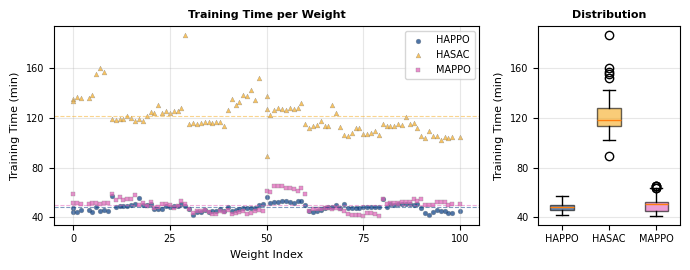

In [23]:
# if WANDB_AVAILABLE and USE_WANDB_API:
print("\n--- Training Time per Algorithm (minutes) ---")
for algo in sorted(time_df["algorithm"].unique()):
    algo_times = time_df[time_df["algorithm"] == algo]["duration_min"]
    print(f"  {algo}: mean={algo_times.mean():.2f} ± std={algo_times.std():.2f}  "
            f"[min={algo_times.min():.2f}, max={algo_times.max():.2f}]  "
            f"(n={len(algo_times)}) "
            f"Full training time: {algo_times.sum():.1f} min ({algo_times.sum() / 60:.1f} hrs)")

if not time_df.empty:
    fig_time = plot_training_time(time_df)
    if SAVE_FIGURES:
        fig_time.savefig(OUTPUT_DIR / "training_time.png", dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
else:
    print("No training time data available")